# Approach Risk 1.2 – Altitude Forecasting Pipeline

LFPG 09L: PostgreSQL → SQL → модели → MLflow. Реальный запуск на локальных данных 2025 года

## Задача и протокол

Прогнозируем последующую наблюдаемую высоту через 27–33 секунды. Физический baseline продолжает текущую вертикальную скорость; модели учат поправку. Девять train-дней, три validation-дня и три test-дня перенесены из 1.1. Каждый заход имеет равный вес. Scaler обучается на train; параметры моделей и early stopping выбираются по validation

In [1]:
# Загружаем сохраненные результаты без повторного обучения
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = Path.cwd()
display(pd.read_csv(root / "reports/split_inventory.csv"))

,season,split,rows,events
0,autumn,test,1074,14
1,autumn,train,3401,48
2,autumn,validation,1088,14
3,spring,test,366,24
4,spring,train,5315,282
5,spring,validation,1694,88
6,summer,test,484,17
7,summer,train,1999,54
8,summer,validation,510,12


## PostgreSQL и качество

Первая загрузка: 15 931 строка. Повторная: ноль новых строк. Извлечение сохранило все значения. Ключ наблюдения: airport + event_id + origin_time. SQL JOIN присоединяет фиксированный split дня; CTE считает ошибки с равным вкладом заходов

In [2]:
# Показываем состав данных из SQL и проверку физических соотношений
display(pd.read_csv(root / "reports/sql/01.csv"))
display(pd.read_csv(root / "reports/sql/07.csv"))

,airport,season,split,pairs,events
0,LFPG,autumn,test,1074,14
1,LFPG,autumn,train,3401,48
2,LFPG,autumn,validation,1088,14
3,LFPG,spring,test,366,24
4,LFPG,spring,train,5315,282
5,LFPG,spring,validation,1694,88
6,LFPG,summer,test,484,17
7,LFPG,summer,train,1999,54
8,LFPG,summer,validation,510,12


,airport,horizon_difference_s,baseline_difference_ft,residual_difference_ft
0,LFPG,0.0,0.0,0.0


## Итоговое сравнение

Test содержит 55 заходов. MAE сначала усредняется внутри захода, затем между заходами. RMSE – квадратный корень из среднего по заходам MSE. Все варианты зафиксированы до вычисления test-метрик; новый подбор по test не проводится

,model,macro_mae_ft,macro_rmse_ft,run_id
0,Constant vertical rate,49.348959,67.995818,af81171321ba41da902589bff85a3858
1,Ridge,20.033286,25.796078,58f9e5e9015e4478b4c9631b4aa613d0
2,Polynomial Ridge,17.163963,22.244615,54224c6909c1451aa7c24c45feaa2dc5
3,PyTorch MLP,18.862559,24.466738,e1e47564e32845768281b8f447e7e21b


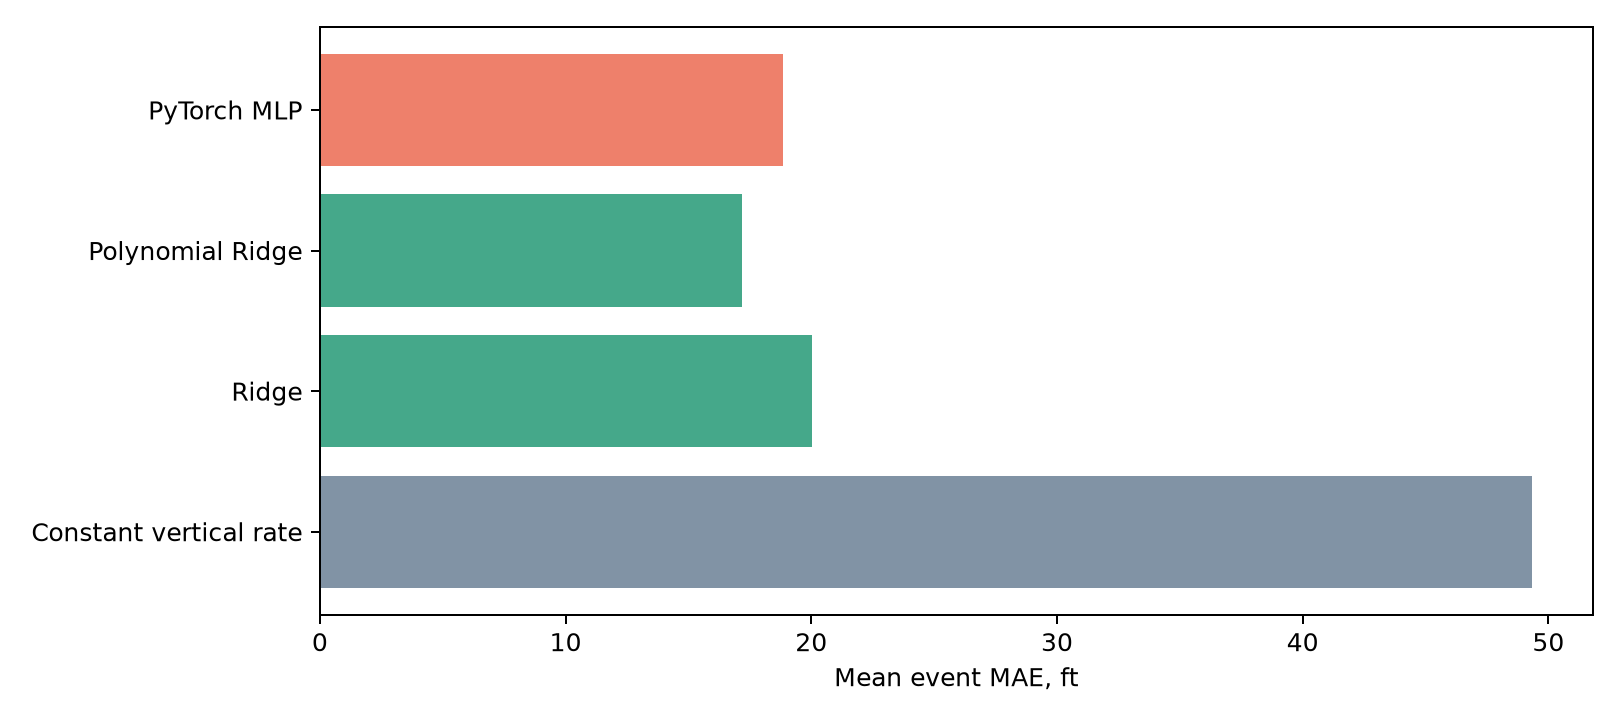

In [3]:
# Показываем измеренные метрики и график сравнения
display(pd.read_csv(root / "reports/model_metrics.csv"))
display(Image(filename=str(root / "reports/model_comparison.png")))

## PyTorch

MLP с двумя скрытыми слоями и ReLU учит residual. DataLoader перемешивает только train. Взвешенный MSE сохраняет равный вклад заходов. Adam, seed 20261014, ширина 16 или 32, до 300 эпох; остановка после 30 эпох без улучшения validation MAE

,model,parameter,validation_macro_mae_ft
0,Ridge,1,17.420799
1,Ridge,10,17.684009
2,Ridge,100,19.099109
3,Polynomial Ridge,1,16.990514
4,Polynomial Ridge,10,17.304185
5,Polynomial Ridge,100,18.478840
6,PyTorch MLP,16,17.064349
7,PyTorch MLP,32,17.105717


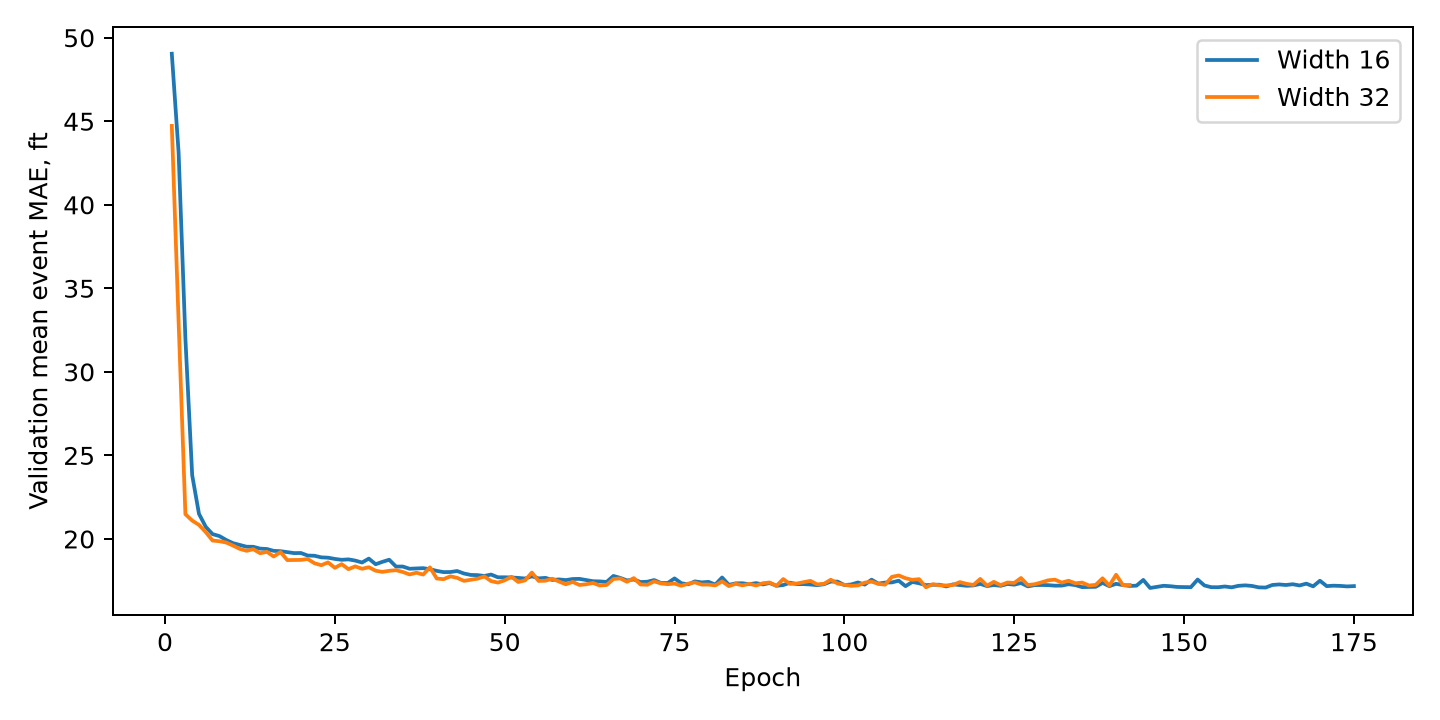

In [4]:
# Проверяем выбор параметров по валидации без обращения к тестовой выборке
display(pd.read_csv(root / "reports/validation_search.csv"))
display(Image(filename=str(root / "reports/mlp_validation.png")))

## Усреднение ошибки по заходам

GROUP BY сначала вычисляет MAE каждого захода; CTE хранит промежуточный результат в пределах запроса. Затем ошибки усредняются между заходами. При усреднении по строкам вклад захода пропорционален числу пар. На тесте baseline: 49.35 ft по заходам и 51.58 ft по строкам. Количество пар зависит от плотности и пригодности наблюдений, поэтому не равно длительности захода

,airport,split,events,pairs,event_macro_mae_ft,row_mae_ft,min_pairs,median_pairs,max_pairs,pairs_mae_correlation
0,LFPG,test,55,1924,49.348959,51.575738,8,21.0,97,0.119039
1,LFPG,train,384,10715,57.733716,55.591887,7,20.0,96,-0.100664
2,LFPG,validation,114,3292,54.290466,50.220412,13,20.0,98,-0.179115


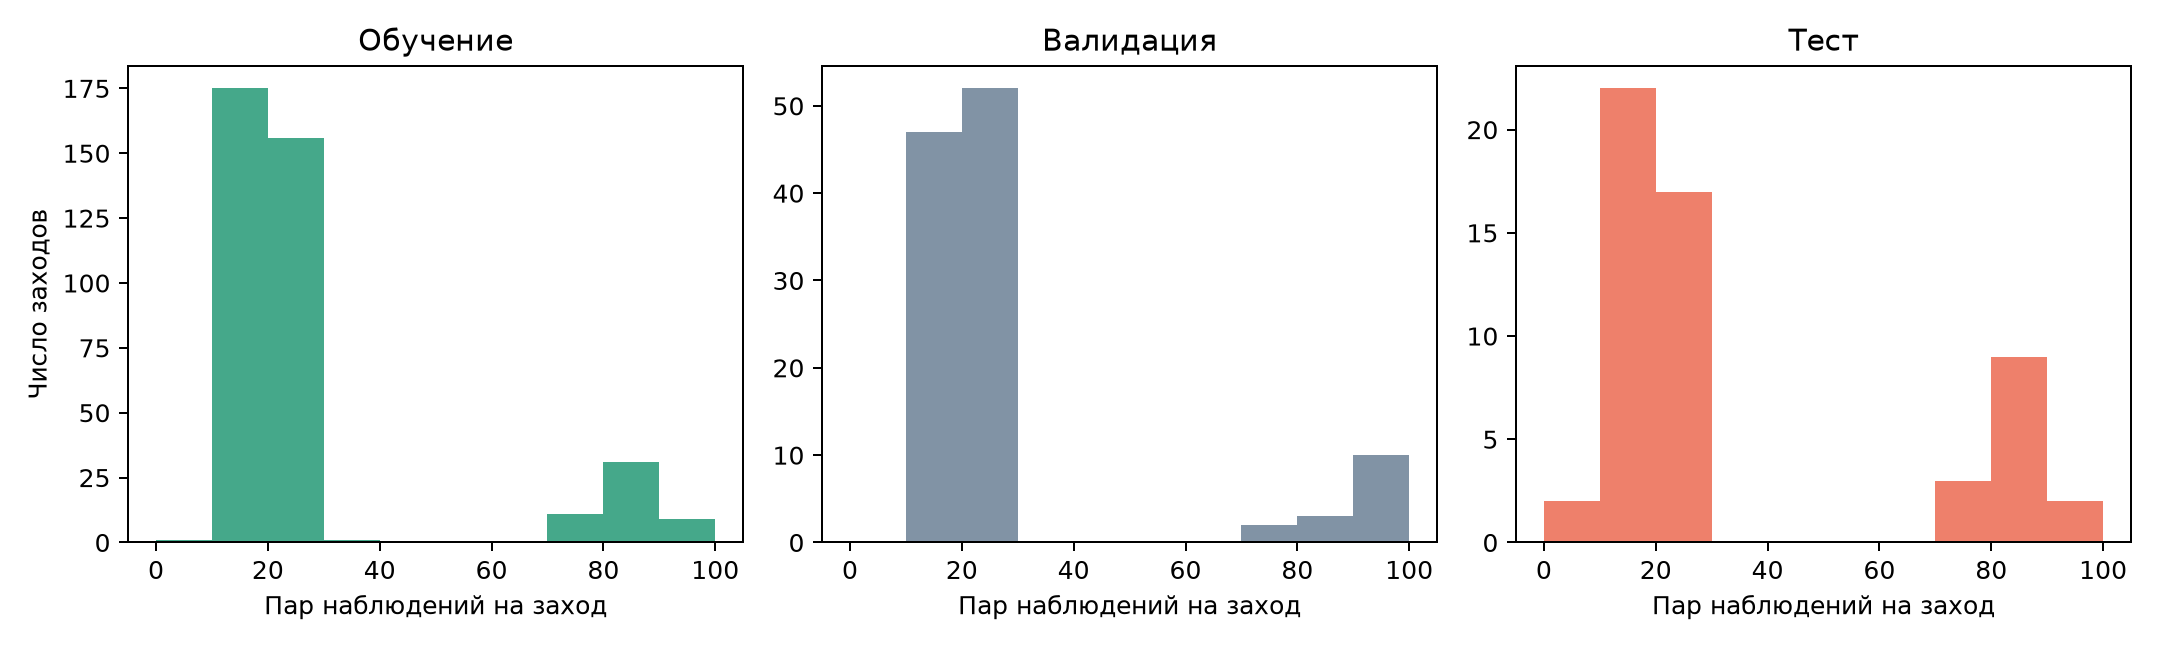

In [5]:
# Показываем независимый SQL-расчет и распределение числа пар
display(pd.read_csv(root / "reports/sql/event_mae_01.csv"))
display(Image(filename=str(root / "reports/event_pair_distribution.png")))

## Интерпретация и ограничения

MLP улучшила физический baseline, но уступила Polynomial Ridge на этом тесте. Это результат ограниченного эксперимента, без доказательства общего превосходства модели. Данные относятся к одной полосе и отобранным погожим дням. Между split повторяются борта. Фактический горизонт известен ретроспективно и входит в признаки. Строгий онлайн-горизонт 30 секунд, go-around и эксплуатационная безопасность не проверены